# Parte Comum: Passada 1 (K-Means sobre o dataset Obesity)

Agrupamos as pessoas do dataset **Obesity (UCI 544)** com K-Means usando só as variáveis numéricas, **sem olhar o rótulo** `NObeyesdad`. Só no final comparamos os grupos com a classe real.

A lógica fica em `src/parte_comum/` (com testes em `tests/`); este notebook só chama as funções e mostra os resultados.

In [1]:
# [IA] Claude Code – importação das bibliotecas e das funções de src/parte_comum
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(RAIZ / 'src'))

from parte_comum.avaliacao import avaliar
from parte_comum.clustering import (
    ajustar_kmeans, aplicar_mapa, kmeans_inercias, mapear_clusters, projetar_2d,
)
from parte_comum.preprocessing import ALVO, NUMERICAS, carregar_obesity, padronizar
from parte_comum.visualizacao import plotar_clusters, plotar_cotovelo

SAIDA = RAIZ / 'out' / 'parte_comum'
SAIDA.mkdir(parents=True, exist_ok=True)
SEMENTE = 42

## 1. Padronizar as variáveis

As 8 variáveis numéricas têm escalas muito diferentes (idade em anos, altura em metros, peso em kg). Sem padronizar, o K-Means seria dominado pelas de maior escala. Aplicamos z-score (média 0, desvio 1).

In [2]:
# [IA] Claude Code – leitura do Obesity e padronização z-score das variáveis numéricas
df = carregar_obesity(RAIZ / 'data' / 'parte_comum' / 'obesity.csv')
X = padronizar(df, NUMERICAS)
print(f'{len(df)} linhas, {len(NUMERICAS)} variáveis numéricas')
X.describe().loc[['mean', 'std']].round(3)

2111 linhas, 8 variáveis numéricas


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
mean,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 2. K-Means com k de 2 a 10 e Método do Cotovelo

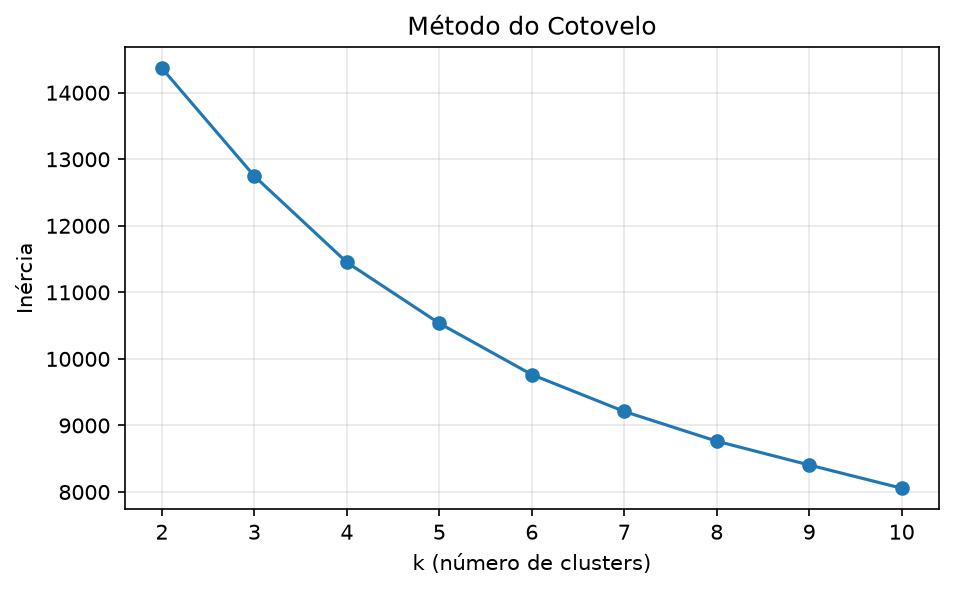

,inercia
2,14368.0
3,12746.7
4,11451.6
5,10534.9
6,9764.3
7,9210.4
8,8763.7
9,8406.0
10,8056.6


In [3]:
# [IA] Claude Code – inércia do K-Means para k de 2 a 10 e gráfico do Método do Cotovelo
inercias = kmeans_inercias(X, range(2, 11), random_state=SEMENTE)
fig = plotar_cotovelo(inercias)
fig.savefig(SAIDA / 'passada1_cotovelo.png', dpi=150, bbox_inches='tight')
display(Image(filename=SAIDA / 'passada1_cotovelo.png'))
inercias.round(1).to_frame()

**Leitura do cotovelo.** A queda da inércia é gradual, sem um "joelho" nítido: cada k adicional reduz a inércia de forma parecida. O método sozinho não indica um k único. Adotamos **k = 7**, o número de classes reais de `NObeyesdad`, para poder comparar grupos e classes na etapa de avaliação.

In [4]:
# [IA] Claude Code – K-Means com k = 7 (número de classes reais)
K = 7
labels = ajustar_kmeans(X, k=K, random_state=SEMENTE)
pd.Series(labels).value_counts().sort_index().to_frame('amostras')

,amostras
0,280
1,363
2,253
3,367
4,261
5,334
6,253


## 3. Visualizar os grupos

Projetamos as 8 variáveis padronizadas em 2 componentes principais (PCA) só para desenhar. O agrupamento em si foi feito nas 8 dimensões.

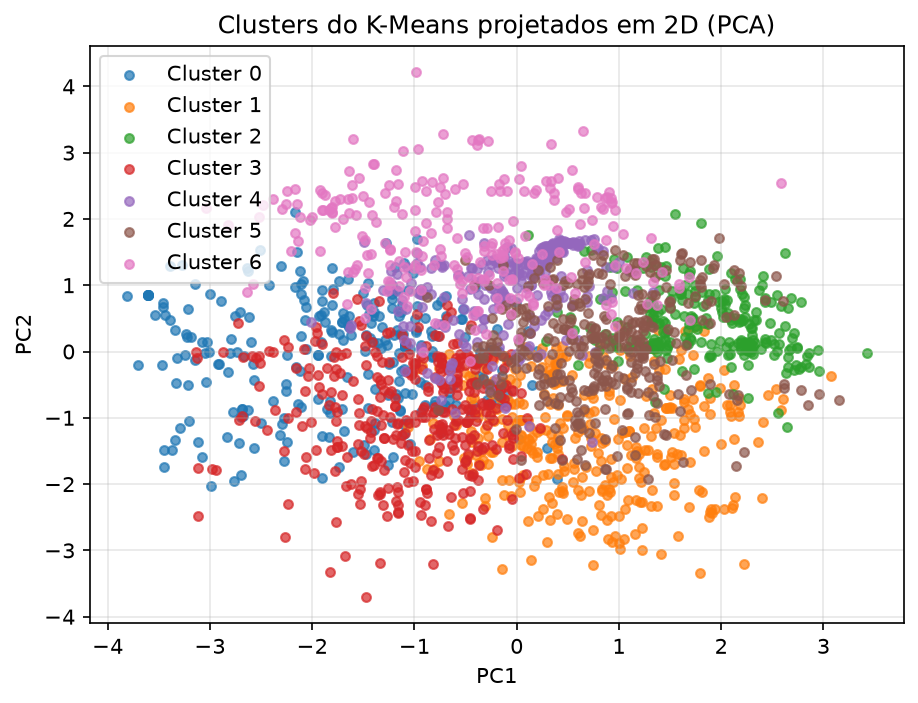

In [5]:
# [IA] Claude Code – projeção PCA em 2D e gráfico dos clusters
proj = projetar_2d(X, random_state=SEMENTE)
fig = plotar_clusters(proj, labels)
fig.savefig(SAIDA / 'passada1_clusters_pca.png', dpi=150, bbox_inches='tight')
display(Image(filename=SAIDA / 'passada1_clusters_pca.png'))

## 4. Mapear cada cluster para a classe majoritária

K-Means não sabe o nome das classes. Rotulamos cada cluster com a classe real mais frequente dentro dele (empate: ordem alfabética, para ser determinístico).

In [6]:
# [IA] Claude Code – mapeamento de cada cluster para a classe majoritária
mapa = mapear_clusters(labels, df[ALVO])
previstas = aplicar_mapa(labels, mapa)
pd.Series(mapa, name='classe majoritária').rename_axis('cluster').to_frame()

,classe majoritária
cluster,
0,Overweight_Level_I
1,Insufficient_Weight
2,Obesity_Type_III
3,Normal_Weight
4,Obesity_Type_III
5,Obesity_Type_II
6,Obesity_Type_I


## 5. Matriz de confusão, acurácia, precisão e recall

In [7]:
# [IA] Claude Code – matriz de confusão, acurácia, precisão e recall
r = avaliar(df[ALVO], previstas)
r['matriz_confusao'].to_csv(SAIDA / 'passada1_matriz_confusao.csv')
print(f"Acurácia: {r['acuracia']:.3f}")
print(f"Precisão (macro): {r['precisao']:.3f}")
print(f"Recall (macro): {r['recall']:.3f}")
r['matriz_confusao']

Acurácia: 0.388
Precisão (macro): 0.310
Recall (macro): 0.384


,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
Insufficient_Weight,125,84,3,0,7,53,0
Normal_Weight,83,102,11,16,26,49,0
Obesity_Type_I,38,55,79,95,30,54,0
Obesity_Type_II,0,0,53,126,89,29,0
Obesity_Type_III,0,0,0,0,324,0,0
Overweight_Level_I,65,69,44,34,14,64,0
Overweight_Level_II,52,57,63,63,24,31,0


## Conclusão

Os grupos do K-Means coincidem só parcialmente com as classes de obesidade (acurácia bem abaixo de 50%). Isso é esperado: as classes são definidas pelo IMC (peso e altura), mas o K-Means usa as 8 variáveis com o mesmo peso, e boa parte delas (hábitos alimentares e de atividade física) não separa as classes. Detalhes no relatório.